# Fast-fail analysis — AE trivial inversion (latent recovery)

**Question**: can the foundation model's latent space be navigated by gradient
optimization well enough to represent true velocity models? (the
reparameterized-FWI premise)

**Data**: `notebooks/data/` — extracted from MLflow experiment
`encdec.highres.inversion` by `notebooks/data/extract_from_mlflow.py`.
Provenance and column meanings: `notebooks/data/DATA_DICTIONARY.md`.

**Campaign**: 4 refit ML models (encdec 3×3 seed 7, encdec 5×5 seed 79,
encdec 7×7 seed 571, transencdec 5×5 seed 571) × 4 latent inits ×
5 lrs × 4 epoch budgets; every run inverts the SAME 3 target models —
the hardcoded inverted test indices [1, 10, 20], hand-picked difficult
examples from the refit's test set (whose 100-model MCCV holdout is
logged as context only). The extract carries the **323 ACTIVE runs** of
the experiment (standing rule: active only); **320 form the clean set**
(the complete factorial).

Reading order: audit the cleaning (cell 2) → sweep map (3) → final-state
tables (4) → per-example results (5) → example identity (6) →
best-so-far (8) → difficulty spread (9) →
best-so-far (8) → difficulty spread (9) →
verdict (10) — then the fast-fail verdict pack (cells 11–15).

In [17]:
from pathlib import Path
import pandas as pd

DATA = Path("data") if Path("data/runs.csv").exists() else Path("notebooks/data")
runs = pd.read_csv(DATA / "runs.csv", parse_dates=["start_time_iso"])
print("preview of runs:")
display(runs.head())
print("total runs:", len(runs), "(active only — standing run-lifecycle rule)")
display(runs["group"].value_counts().rename("runs").to_frame())

sweep = runs[runs["group"] == "sweep_full_samples"].copy()
kept = sweep[sweep["kept_in_clean_set"] == True].copy()     # noqa: E712
print(f"sweep {len(sweep)} = kept {len(kept)} (one run per combo)")
assert len(runs) == 323 and len(kept) == 320, "unexpected extract shape"
assert len(kept) == kept["combo"].nunique(), "kept must be one row per combo"
# Standing rule (user, 2026-11-24, valid forever): obsolete/play runs are
# deleted from MLflow before results are taken; kept test runs are renamed.
# The extract carries ACTIVE runs only — the 137 soft-deleted runs of this
# campaign are documented in DATA_DICTIONARY.md but are not in this data.

print("\nkept runs per refit ML model:")
display(kept.groupby(["arch_family", "kernel", "seed", "refit_short"])
        .size().rename("kept").to_frame())

preview of runs:


,run_id,run_name,group,kept_in_clean_set,has_valid_metrics,combo,refit_short,arch_family,kernel,seed,...,inversion_mse_mean_test_set,inversion_mse_min_test_set,inversion_mse_std_test_set,inversion_mse_values,inversion_ssim_max_test_set,inversion_ssim_mean_test_set,inversion_ssim_min_test_set,inversion_ssim_std_test_set,inversion_ssim_values,train_loss
0,a337bb35af9644bab39255ce7feecc69,REFIT__ENCDEC_INVERSION_32409900943c44f7ae798d...,sweep_full_samples,True,True,32409900|trained|lr=0.001|ep=1000,32409900,transencdec,5,571,...,0.007901,0.004122,0.004336,0.005610,0.813748,0.782308,0.750295,0.025908,0.782880,0.005643
1,57fa1be750834c9abb5a3f54eb85e95f,REFIT__ENCDEC_INVERSION_9247757e7e0f49459ee4fe...,sweep_full_samples,True,True,9247757e|trained|lr=0.001|ep=1000,9247757e,encdec,5,79,...,0.007038,0.005172,0.002090,0.009957,0.849879,0.832006,0.818519,0.013173,0.849879,0.010200
2,e9cf4d14b09c4a1fa1f1f010460d8564,REFIT__ENCDEC_INVERSION_32409900943c44f7ae798d...,sweep_full_samples,True,True,32409900|zeros|lr=0.001|ep=1000,32409900,transencdec,5,571,...,0.004867,0.001429,0.004070,0.002589,0.873858,0.838798,0.797834,0.031316,0.844701,0.002686
3,4489d2d5d66e44368fc35ac7948d03c9,REFIT__ENCDEC_INVERSION_9247757e7e0f49459ee4fe...,sweep_full_samples,True,True,9247757e|zeros|lr=0.001|ep=1000,9247757e,encdec,5,79,...,0.004954,0.003651,0.001305,0.006737,0.901921,0.881191,0.865491,0.015292,0.901921,0.007053
4,0e9575e0d59e424280fd115c8dd1c311,REFIT__ENCDEC_INVERSION_32409900943c44f7ae798d...,sweep_full_samples,True,True,32409900|randomn|lr=0.001|ep=1000,32409900,transencdec,5,571,...,0.006495,0.002901,0.004458,0.003805,0.846747,0.814501,0.768982,0.033106,0.827773,0.003831


total runs: 323 (active only — standing run-lifecycle rule)


,runs
group,
sweep_full_samples,320
tst_sanity,3


sweep 320 = kept 320 (one run per combo)

kept runs per refit ML model:


kept
arch_family kernel seed refit_short      
encdec      3      7    6d115baa       80
            5      79   9247757e       80
            7      571  b01fdd28       80
transencdec 5      571  32409900       80

In [18]:
# Sweep map: is the 4x5x4 factorial complete for every refit model?
INITS = ["trained", "zeros", "random", "randomn"]
LRS = [0.001, 0.01, 0.1, 0.5, 1.0]
BUDGETS = [50, 100, 500, 1000]
key_cols = ["refit_short", "latent_init", "lr", "max_epochs"]

present = set(map(tuple, kept[key_cols].itertuples(index=False, name=None)))
expected = {(r, i, float(lr), float(ep))
            for r in kept["refit_short"].unique()
            for i in INITS for lr in LRS for ep in BUDGETS}
print(f"grid cells present: {len(present & expected)} / {len(expected)}")
print("missing:", sorted(expected - present) or "none")

outside = kept[~kept[key_cols].apply(lambda r: tuple(r) in expected, axis=1)]
print("outside the 4x5x4 grid:", len(outside),
      "(none expected — the 200-ep probe was soft-deleted in the curation)")
assert len(outside) == 0, "unexpected non-grid runs in the active set"

# Duplicate re-runs are also absent from this extract by the standing rule:
# they were soft-deleted in the same manual curation. They were numerical
# replicates (same latent init; measured spread 0 except at the lr=1.0
# batch switch) — see DATA_DICTIONARY.md and docs/refactor-plan.md.

grid cells present: 320 / 320
missing: none
outside the 4x5x4 grid: 0 (none expected — the 200-ep probe was soft-deleted in the curation)


In [19]:
# Final-state tables. CAVEAT: 'final' = state at schedule end; with
# cosine_annealing_wr that can be a peak-lr point (quantified in the next cells).
mse = "inversion_mse_mean_test_set"
ssim = "inversion_ssim_mean_test_set"

for ep in [1000, 500, 100, 50]:
    sub = kept[kept["max_epochs"] == ep]
    t = sub.pivot_table(index="latent_init", columns="lr", values=mse, aggfunc="mean")
    print(f"\n=== final MSE @ {ep} epochs — mean over the 4 refit ML models "
          f"(each run = mean over its 3 inverted targets, the difficult "
          f"examples [1, 10, 20]) ===")
    display(t.round(4))

print("\n=== per-init best across all 20 (lr, budget) combos ===")
per_combo = kept.groupby(["latent_init", "lr", "max_epochs"])[mse].mean().reset_index()
display(per_combo.loc[per_combo.groupby("latent_init")[mse].idxmin()].round(4))

print("\n=== per refit ML model, clean grid (all budgets) ===")
display(kept.groupby(["arch_family", "kernel", "seed"])[mse]
        .agg(["count", "mean", "min", "max"]).round(4))

t = kept[kept["max_epochs"] == 1000].pivot_table(index="latent_init", columns="lr",
                                                 values=ssim, aggfunc="mean")
print("\n=== final SSIM @ 1000 epochs ===")
display(t.round(3))


=== final MSE @ 1000 epochs — mean over the 4 refit ML models (each run = mean over its 3 inverted targets, the difficult examples [1, 10, 20]) ===


lr,0.001,0.010,0.100,0.500,1.000
latent_init,,,,,
random,0.0056,0.0045,0.0045,0.0050,0.0053
randomn,0.0062,0.0046,0.0045,0.0047,0.0050
trained,0.0065,0.0044,0.0043,0.0044,0.0044
zeros,0.0047,0.0047,0.0060,0.0087,0.0105



=== final MSE @ 500 epochs — mean over the 4 refit ML models (each run = mean over its 3 inverted targets, the difficult examples [1, 10, 20]) ===


lr,0.001,0.010,0.100,0.500,1.000
latent_init,,,,,
random,0.0070,0.0048,0.0049,0.0057,0.0065
randomn,0.0077,0.0049,0.0047,0.0052,0.0055
trained,0.0088,0.0047,0.0044,0.0045,0.0046
zeros,0.0050,0.0051,0.0076,0.0120,0.0148



=== final MSE @ 100 epochs — mean over the 4 refit ML models (each run = mean over its 3 inverted targets, the difficult examples [1, 10, 20]) ===


lr,0.001,0.010,0.100,0.500,1.000
latent_init,,,,,
random,0.0134,0.0059,0.0063,0.0087,0.0104
randomn,0.0192,0.0067,0.0059,0.0073,0.0090
trained,0.0165,0.0068,0.0049,0.0053,0.0056
zeros,0.0068,0.0077,0.0137,0.0198,0.0225


... (4 outputs left out)


=== per refit ML model, clean grid (all budgets) ===


count    mean     min     max
arch_family kernel seed                               
encdec      3      7        80  0.0088  0.0037  0.0419
            5      79       80  0.0086  0.0044  0.0287
            7      571      80  0.0086  0.0047  0.0263
transencdec 5      571      80  0.0093  0.0044  0.0297


=== final SSIM @ 1000 epochs ===


lr,0.001,0.010,0.100,0.500,1.000
latent_init,,,,,
random,0.851,0.873,0.874,0.873,0.870
randomn,0.836,0.872,0.871,0.872,0.869
trained,0.824,0.869,0.871,0.872,0.873
zeros,0.874,0.870,0.858,0.831,0.820


In [20]:
# Per-example results: every run inverts the SAME 3 target examples (test-set positions
# [1, 10, 20]). The *_values MLflow metrics carry the per-example scalars
# (step t = t-th smallest inverted index — see log_evaluation_results);
# (vocabulary: 'model' = ML model; dataset items are 'examples' — legacy
#  identifiers keep the old wording: model_idx = example index)
# the extract maps them to model_idx in inversion_per_model.csv.
per_model = pd.read_csv(DATA / "inversion_per_model.csv")
pm = per_model[per_model["run_id"].isin(kept["run_id"])].copy()  # analysis set = kept (grid-only after cell 3)
print("per-example rows:", len(pm), "| runs:", pm["run_id"].nunique())

# (a) which target is hardest? per-example metrics averaged over all clean runs
print("=== per-example averages over all clean runs (difficulty of each target example) ===")
display(pm.groupby("model_idx")[["mse", "mae", "ssim"]].mean().round(4)
        .rename_axis(index="example_idx"))  # displayed as example_idx

# (b) per-model final MSE @ 1000 epochs: init x lr, one table per target
for idx, g in pm.groupby("model_idx"):
    sub = g[g["max_epochs"] == 1000]
    t = sub.pivot_table(index="latent_init", columns="lr", values="mse", aggfunc="mean")
    print(f"\n=== example (test-set position) {idx}: final MSE @ 1000 epochs ===")
    display(t.round(4))

# (c) the 3-example aggregate vs the per-example spread it hides
agg = kept.set_index("run_id")["inversion_mse_mean_test_set"].rename("agg_mean")
spread = pm.groupby("run_id")["mse"].agg(pm_min="min", pm_max="max")
c3 = pd.concat([agg, spread], axis=1).dropna()
c3["max/min"] = c3["pm_max"] / c3["pm_min"]
print("=== 3-example aggregate vs the per-example spread it hides ===")
display(c3.describe().round(3))

per-example rows: 960 | runs: 320
=== per-example averages over all clean runs (difficulty of each target example) ===


,mse,mae,ssim
example_idx,,,
1,0.0060,0.0553,0.8485
10,0.0132,0.0948,0.8129
20,0.0073,0.0645,0.8390



=== example (test-set position) 1: final MSE @ 1000 epochs ===


lr,0.001,0.010,0.100,0.500,1.000
latent_init,,,,,
random,0.0035,0.0026,0.0026,0.0030,0.0033
randomn,0.0039,0.0026,0.0025,0.0027,0.0029
trained,0.0041,0.0025,0.0024,0.0024,0.0025
zeros,0.0027,0.0027,0.0037,0.0053,0.0066



=== example (test-set position) 10: final MSE @ 1000 epochs ===


lr,0.001,0.010,0.100,0.500,1.000
latent_init,,,,,
random,0.0090,0.0075,0.0076,0.0081,0.0085
randomn,0.0095,0.0076,0.0075,0.0079,0.0083
trained,0.0098,0.0074,0.0074,0.0074,0.0075
zeros,0.0078,0.0079,0.0096,0.0137,0.0164



=== example (test-set position) 20: final MSE @ 1000 epochs ===


lr,0.001,0.010,0.100,0.500,1.000
latent_init,,,,,
random,0.0044,0.0034,0.0034,0.0038,0.0042
randomn,0.0050,0.0034,0.0033,0.0036,0.0038
trained,0.0056,0.0034,0.0032,0.0032,0.0033
zeros,0.0036,0.0036,0.0048,0.0070,0.0085


=== 3-example aggregate vs the per-example spread it hides ===


,agg_mean,pm_min,pm_max,max/min
count,320.000,320.000,320.000,320.000
mean,0.009,0.005,0.015,3.782
std,0.006,0.005,0.009,2.027
min,0.004,0.001,0.006,1.212
25%,0.005,0.002,0.009,1.937
50%,0.007,0.004,0.011,3.323
75%,0.010,0.006,0.017,5.013
max,0.042,0.032,0.055,14.580


## Example identity — what distinguishes the three inverted examples

**Mechanism**: the per-example scalars ride in the `inversion_*_values`
metric series, logged with `step` = position in the sorted inverted list
([1, 10, 20]) — the extract maps step → example position. Positions are
0-based indices into each refit ML model's own 100-example holdout, so
the SAME position is a DIFFERENT dataset example per seed (the two
seed-571 ML models share their split).

In [21]:
inv_ex = pd.read_csv(DATA / "inverted_examples.csv")
display(inv_ex)  # holdout position -> dataset example index, per refit ML model

# difficulty per position, per refit ML model — comment (i) made concrete
diff = pm.groupby(["refit_short", "model_idx"])["mse"].mean().round(4).unstack()
diff.columns = [f"pos {c}" for c in diff.columns]
print("=== average inversion MSE per position, per refit ML model ===")
display(diff)

,refit_run_id,refit_short,arch_family,kernel,seed,holdout_size,model_step,example_pos,dataset_example_idx
0,32409900943c44f7ae798d3cf2d57ed1,32409900,transencdec,5,571,100,0,1,429
1,32409900943c44f7ae798d3cf2d57ed1,32409900,transencdec,5,571,100,1,10,63
2,32409900943c44f7ae798d3cf2d57ed1,32409900,transencdec,5,571,100,2,20,239
3,6d115baa522d44ccb0a570ac42caf302,6d115baa,encdec,3,7,100,0,1,921
4,6d115baa522d44ccb0a570ac42caf302,6d115baa,encdec,3,7,100,1,10,741
5,6d115baa522d44ccb0a570ac42caf302,6d115baa,encdec,3,7,100,2,20,891
6,9247757e7e0f49459ee4fe8e897fcd14,9247757e,encdec,5,79,100,0,1,476
7,9247757e7e0f49459ee4fe8e897fcd14,9247757e,encdec,5,79,100,1,10,696
8,9247757e7e0f49459ee4fe8e897fcd14,9247757e,encdec,5,79,100,2,20,5
9,b01fdd281f6d465082da2cb433f9c989,b01fdd28,encdec,7,571,100,0,1,429


=== average inversion MSE per position, per refit ML model ===


,pos 1,pos 10,pos 20
refit_short,,,
32409900,0.0055,0.0161,0.0062
6d115baa,0.0073,0.0135,0.0055
9247757e,0.0072,0.0068,0.0119
b01fdd28,0.0039,0.0163,0.0057


In [22]:
# Baseline gap: refit prediction (mean over its 100-example holdout) vs trivial
# inversion (mean over the 3 hand-picked DIFFICULT targets [1, 10, 20]).
# Difficulty mismatch inflates the gap; cell 7 (best-so-far) quantifies the
# final-state artifact on top of that.
base = pd.read_csv(DATA / "refit_baselines.csv").set_index("refit_short")

inv = kept[kept["max_epochs"] == 1000].pivot_table(
    index="refit_short", columns="latent_init", values=mse, aggfunc="mean")
cmp = pd.DataFrame({
    "refit_mse": base["mse_mean_test_set"],
    "inv@1000_mean_over_inits": inv.mean(axis=1),
    "inv@1000_best_init": inv.min(axis=1),
})
cmp["ratio_mean"] = cmp["inv@1000_mean_over_inits"] / cmp["refit_mse"]
cmp["refit_ssim"] = base["ssim_mean_test_set"]
inv_ssim = kept[kept["max_epochs"] == 1000].pivot_table(
    index="refit_short", columns="latent_init", values=ssim, aggfunc="mean")
cmp["inv_ssim@1000_mean"] = inv_ssim.mean(axis=1)

print("=== refit prediction vs trivial inversion ===")
display(cmp.round(4))

=== refit prediction vs trivial inversion ===


,refit_mse,inv@1000_mean_over_inits,inv@1000_best_init,ratio_mean,refit_ssim,inv_ssim@1000_mean
refit_short,,,,,,
32409900,0.0012,0.0057,0.005,4.8525,0.8930,0.8268
6d115baa,0.0009,0.0051,0.004,5.7496,0.8991,0.8840
9247757e,0.0008,0.0054,0.005,6.5241,0.9053,0.8671
b01fdd28,0.0011,0.0055,0.005,5.0269,0.8988,0.8663


/tmp/ipykernel_1736740/350589593.py:10: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  hpe = pd.read_csv(DATA / "train_loss_per_example.csv")


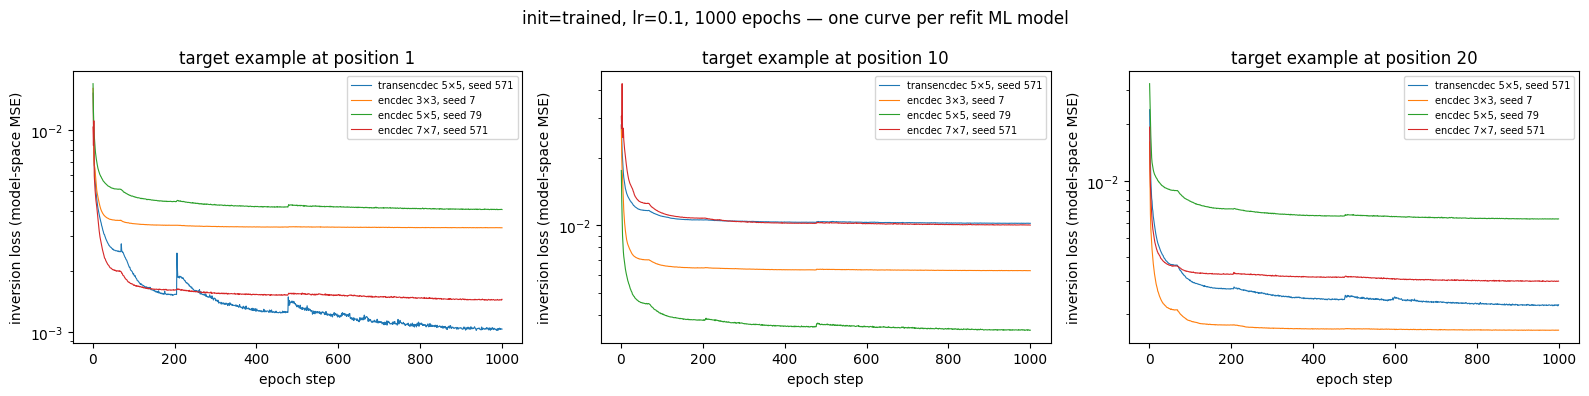

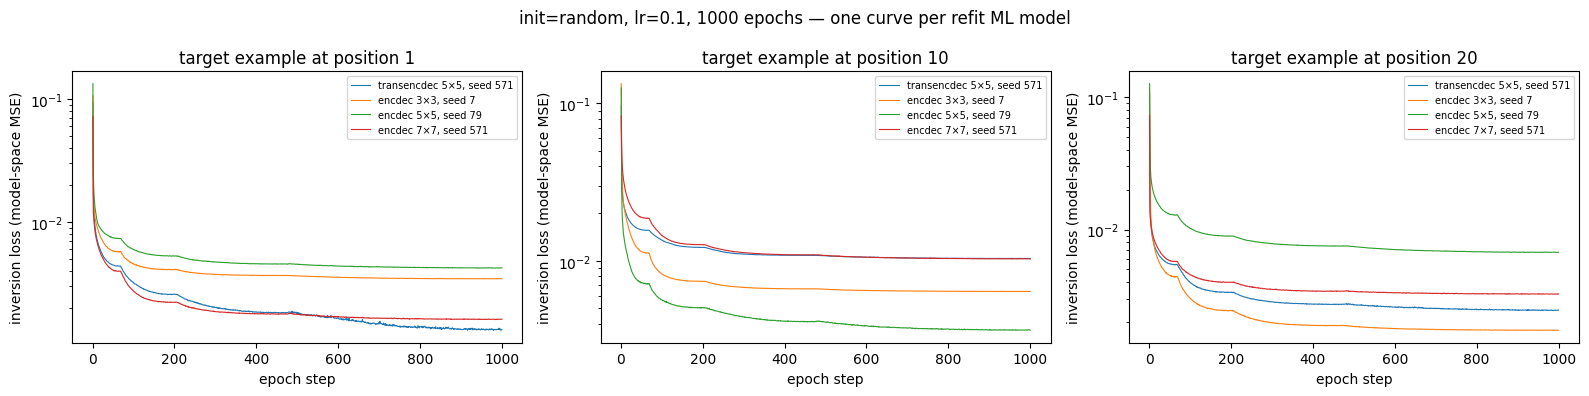

=== per-example best-so-far vs final state (320 runs x 3 examples) ===


,best_so_far,final_mse,final/best
count,960.0000,960.0000,960.0000
mean,0.0089,0.0088,0.9964
std,0.0077,0.0077,0.3719
min,0.0010,0.0009,0.7926
25%,0.0037,0.0036,0.9685
50%,0.0065,0.0064,0.9815
75%,0.0114,0.0114,0.9920
max,0.0578,0.0551,9.2932



worst final/best cases:


,,best_so_far,final_mse,final/best
run_id,model_idx,,,
9d7a3f8d37a942009206ab1d7f92eee1,1,0.0056,0.0522,9.2932
49f1863848c44b6784a645f97a418191,1,0.0045,0.0395,8.7423
cc9ff8ec5a434a4dbb923ee5e172c1c0,1,0.0050,0.0133,2.6439
f53f555bfff2476d80b2d4f543873217,1,0.0088,0.0124,1.4013
fa65febac726492dad0462d374b79478,1,0.0076,0.0086,1.1381
80727df9466442df80e3ca745767dcd6,1,0.0039,0.0041,1.0549
3fb0e619d547484188a04e70813a3003,10,0.0124,0.0129,1.0396
768703f4b24e4e7e8173b85dc31241ae,20,0.0141,0.0145,1.0302
6d82a0e25e7646c0956fa2cab0f18d6a,10,0.0079,0.0081,1.0296



best-so-far floor vs the refit ML models' prediction MSE (~0.0009): 0.0010179546661674


In [23]:
# Convergence, PER EXAMPLE. y-axis = the INVERSION loss (the latent-optimization
# objective: model-space MSE between Generator(z) and the target example) —
# NOT the refit training loss. It is logged under the metric name 'train_loss'
# because the inversion reuses the skorch training machinery to train the latent.
# trajectories (one per target example, logged sequentially — steps restart
# per example); the extract segments them into train_loss_per_example.csv
# (model_idx = the target example's position in the refit ML model's holdout).
import matplotlib.pyplot as plt

hpe = pd.read_csv(DATA / "train_loss_per_example.csv")
curves = (hpe.sort_values("step")
             .groupby(["run_id", "model_idx", "step"], as_index=False)["value"].last())
curves = curves.merge(kept[["run_id", "combo", "refit_short", "arch_family",
                            "kernel", "seed", "latent_init", "lr", "max_epochs"]],
                      on="run_id")
# legend label: kernel size + architecture + seed (the refit run id says nothing)
curves["refit_label"] = (curves["arch_family"] + " " + curves["kernel"].astype(str)
                         + "\u00d7" + curves["kernel"].astype(str)
                         + ", seed " + curves["seed"].astype(str))

for INIT, LR in [("trained", 0.1), ("random", 0.1)]:   # bend these
    sel = curves[(curves["latent_init"] == INIT) & (curves["lr"] == LR)
                 & (curves["max_epochs"] == 1000)]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, midx in zip(axes, [1, 10, 20]):
        g = sel[sel["model_idx"] == midx]
        for refit, gg in g.groupby("refit_short"):
            ax.plot(gg["step"], gg["value"], lw=0.8, label=gg["refit_label"].iloc[0])
        ax.set_yscale("log")
        ax.set_title(f"target example at position {midx}")
        ax.set_xlabel("epoch step")
        ax.set_ylabel("inversion loss (model-space MSE)")
        ax.legend(fontsize=7)
    fig.suptitle(f"init={INIT}, lr={LR}, 1000 epochs — one curve per refit ML model")
    plt.tight_layout()
    plt.show()

# per-example best-so-far vs final state (exact per trajectory now)
bsf = curves.groupby(["run_id", "model_idx"])["value"].min().rename("best_so_far")
fin = per_model.set_index(["run_id", "model_idx"])["mse"].rename("final_mse")
bf = pd.concat([bsf, fin], axis=1).dropna()
bf["final/best"] = bf["final_mse"] / bf["best_so_far"]
print("=== per-example best-so-far vs final state (320 runs x 3 examples) ===")
display(bf.describe().round(4))
print("\nworst final/best cases:")
display(bf.sort_values("final/best", ascending=False).head(10).round(4))
print("\nbest-so-far floor vs the refit ML models' prediction MSE (~0.0009):",
      bf["best_so_far"].min())

per-run spread of per-example MSE over the 3 inverted targets ([1, 10, 20]):


,max/min,inversion_mse_std_test_set
count,320.000,320.000
mean,3.782,0.004
std,2.027,0.003
min,1.212,0.001
25%,1.937,0.002
50%,3.323,0.004
75%,5.013,0.005
max,14.580,0.019



refit baseline spread on the same holdouts:


,refit max/min
refit_short,
32409900,3.23
6d115baa,4.10
9247757e,4.06
b01fdd28,3.84


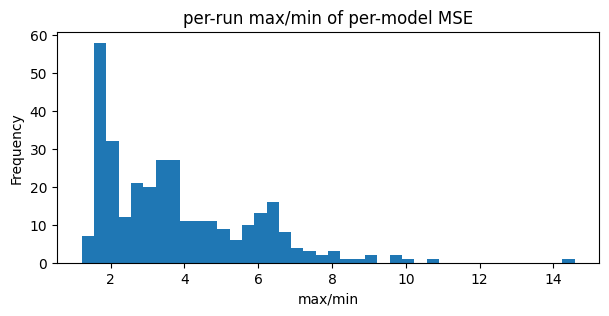

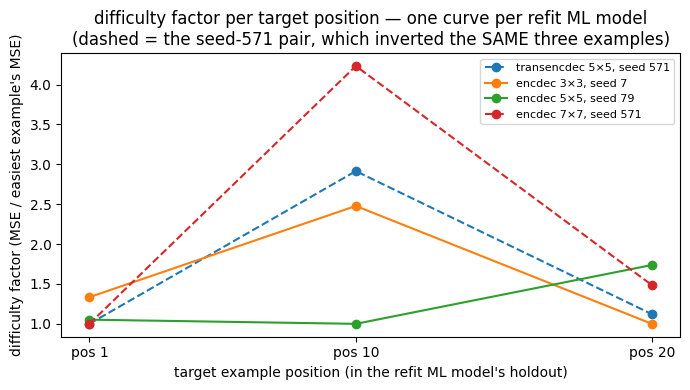

KeyError: "None of ['model_idx'] are in the columns"

In [24]:
# Per-example difficulty spread (comment i): MSE varies a lot across test examples,
# so single-example readings must be difficulty-matched. Here the spread is over
# the 3 inverted targets ([1, 10, 20]) — a small sample, but it brackets the
# difficulty range those specific models span.
spread = kept[["combo", "latent_init", "lr", "max_epochs",
               "inversion_mse_min_test_set", mse,
               "inversion_mse_max_test_set", "inversion_mse_std_test_set"]].copy()
spread["max/min"] = spread["inversion_mse_max_test_set"] / spread["inversion_mse_min_test_set"]

print("per-run spread of per-example MSE over the 3 inverted targets ([1, 10, 20]):")
display(spread[["max/min", "inversion_mse_std_test_set"]].describe().round(3))

refit_spread = (base["mse_max_test_set"] / base["mse_min_test_set"]).rename("refit max/min")
print("\nrefit baseline spread on the same holdouts:")
display(refit_spread.round(2).to_frame())

ax = spread["max/min"].plot(kind="hist", bins=40, figsize=(7, 3),
                            title="per-run max/min of per-model MSE")
ax.set_xlabel("max/min")
plt.show()

# PROOF: is difficulty example-driven or ML-model-driven?
# y = max/min-style factor: MSE(position) / easiest example's MSE within the
# same ML model (easiest = 1.0; a curve's peak = that ML model's max/min).
# Reading: ML models that share the same examples must share the factor
# profile if difficulty belongs to the example. The two seed-571 models
# (7x7 encdec vs transencdec 5x5) inverted the SAME examples (429/63/239)
# with different architectures - the controlled comparison of this campaign.
prof = pm.groupby(["refit_short", "model_idx"], as_index=False)["mse"].mean()
labels = kept.drop_duplicates("refit_short").set_index("refit_short")
label_of = {r: f"{row.arch_family} {int(row.kernel)}\u00d7{int(row.kernel)}, seed {int(row.seed)}"
            for r, row in labels.iterrows()}
prof["factor"] = prof.groupby("refit_short")["mse"].transform(lambda s: s / s.min())
fig, ax = plt.subplots(figsize=(7, 4))
for refit, g in prof.groupby("refit_short"):
    g = g.sort_values("model_idx")
    ls = "--" if refit in ("b01fdd28", "32409900") else "-"
    ax.plot(g["model_idx"], g["factor"], marker="o", ls=ls, label=label_of[refit])
ax.set_xticks([1, 10, 20])
ax.set_xticklabels(["pos 1", "pos 10", "pos 20"])
ax.set_xlabel("target example position (in the refit ML model's holdout)")
ax.set_ylabel("difficulty factor (MSE / easiest example's MSE)")
ax.set_title("difficulty factor per target position — one curve per refit ML model\n"
             "(dashed = the seed-571 pair, which inverted the SAME three examples)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# quantify the controlled comparison: same examples, two different ML models
inv_ex = pd.read_csv(DATA / "inverted_examples.csv")
ex_of = inv_ex[inv_ex.refit_short == "b01fdd28"].set_index("example_pos")["dataset_example_idx"]
p571 = prof[prof["refit_short"].isin(["b01fdd28", "32409900"])]
tab = p571.pivot(index="model_idx", columns="refit_short", values="factor").round(2)
tab.columns = [label_of[c] for c in tab.columns]
tab.index = [f"pos {i} (example {ex_of[i]})" for i in tab.index]
print("=== controlled pair: same examples (429/63/239), two different ML models ===")
display(tab)
rho = tab.corr(method="spearman").iloc[0, 1]
print(f"Spearman rank correlation of the two difficulty profiles (n=3): {rho:.2f}")
print("caveat: example and seed are confounded for the other ML models — each")
print("seed holds its own examples, so this pair is the only controlled")
print("comparison in the campaign; the factor MAGNITUDES may still be")
print("ML-model-dependent even when the ordering is example-driven.")

## Fast-fail verdict pack

Four figures supporting the two core claims:

1. **Experiment grid** — the final-MSE landscape at each budget (init × lr).
2. **Best hyperparameters** — the 16-panel understanding view (4 inits × 4
   refit ML models; per-panel scale, values annotated). A reduced view will
   be planned after reviewing this one.
3. **Reachability** — convergence per init + final state at each init's
   best config: the manifold is reachable from ANY init.
4. **Gap vs baseline** — paired per example: the refit ML model's prediction
   MSE for THAT example vs the inversion's recovery of it (difficulty-matched).

The verdict text is yours to write in the section that follows.

In [ ]:
# 1. EXPERIMENT GRID — final-MSE landscape at each budget (init x lr)
# color = mean over the 3 target examples, pooled over the 4 refit ML models
# palette: magma (perceptual; black = best/low MSE — the emphasized end; light = worst) + PowerNorm(gamma=0.5) for low-range emphasis with a PER-BUDGET min/max scale
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
INITS = ["trained", "zeros", "random", "randomn"]
LRS = [0.001, 0.01, 0.1, 0.5, 1.0]
BUDGETS = [50, 100, 500, 1000]
grid = (kept.groupby(["latent_init", "lr", "max_epochs"], as_index=False)
        ["inversion_mse_mean_test_set"].mean())
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5), sharey=True)
for ax, ep in zip(axes, BUDGETS):
    sub = grid[grid["max_epochs"] == ep]
    M = (sub.pivot(index="latent_init", columns="lr",
                   values="inversion_mse_mean_test_set")
         .reindex(index=INITS, columns=LRS))
    vmin, vmax = M.values.min(), M.values.max()   # per-budget scale
    ax.imshow(M.values, cmap="magma", norm=PowerNorm(gamma=0.5, vmin=vmin, vmax=vmax), aspect="auto")
    ax.set_xticks(range(len(LRS))); ax.set_xticklabels(LRS, rotation=45, fontsize=8)
    ax.set_yticks(range(len(INITS))); ax.set_yticklabels(INITS, fontsize=9)
    for i in range(len(INITS)):
        for j in range(len(LRS)):
            nrm = ((M.values[i, j] - vmin) / (vmax - vmin)) ** 0.5
            ax.text(j, i, f"{M.values[i, j]:.4f}", ha="center", va="center",
                    fontsize=7, color="white" if nrm < 0.45 else "black")
    ax.set_title(f"budget = {ep} epochs (own scale)", fontsize=10)
fig.suptitle("experiment grid — final MSE, lower is better (darker = better)", y=1.06)
plt.tight_layout()
plt.show()

In [ ]:
# 2. BEST HYPERPARAMETERS — 16-panel understanding view (4 inits x 4 refit ML models)
# each panel: budget (rows) x lr (cols); PER-PANEL color scale + annotated MSE
# palette: magma (perceptual; black = best/low MSE — the emphasized end; light = worst) + PowerNorm(gamma=0.5) for low-range emphasis, matching plot 1
REFITS = ["6d115baa", "9247757e", "b01fdd28", "32409900"]
labels = kept.drop_duplicates("refit_short").set_index("refit_short")
label_of = {r: f"{row.arch_family} {int(row.kernel)}\u00d7{int(row.kernel)}, seed {int(row.seed)}"
            for r, row in labels.iterrows()}
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for i, init in enumerate(INITS):
    for j, refit in enumerate(REFITS):
        sub = kept[(kept["latent_init"] == init) & (kept["refit_short"] == refit)]
        M = (sub.pivot(index="max_epochs", columns="lr",
                       values="inversion_mse_mean_test_set")
             .reindex(index=BUDGETS, columns=LRS))
        ax = axes[i, j]
        vmin, vmax = M.values.min(), M.values.max()   # per-panel scale
        ax.imshow(M.values, cmap="magma", norm=PowerNorm(gamma=0.5, vmin=vmin, vmax=vmax), aspect="auto")
        ax.set_xticks(range(len(LRS))); ax.set_xticklabels(LRS, rotation=45, fontsize=7)
        if j == 0:
            ax.set_yticks(range(len(BUDGETS))); ax.set_yticklabels(BUDGETS, fontsize=8)
            ax.set_ylabel(f"init={init}", fontsize=10)
        for a in range(len(BUDGETS)):
            for b in range(len(LRS)):
                nrm = ((M.values[a, b] - vmin) / (vmax - vmin)) ** 0.5
                ax.text(b, a, f"{M.values[a, b]:.4f}", ha="center", va="center",
                        fontsize=6.5, color="white" if nrm < 0.45 else "black")
        ax.set_title(label_of[refit], fontsize=9)
fig.suptitle("best hyperparameters — rows: budget, cols: lr; values = final MSE (mean over 3 examples)",
             y=0.995)
plt.tight_layout()
plt.show()

In [ ]:
# 3. REACHABILITY — best refit ML model only (encdec 5x5, seed 79: lowest
# refit prediction MSE, 0.00083). Column a: convergence per init — the BOLD
# curve is the mean of the THREE inverted examples' trajectories (faint).
# Column b: per init at its best config, a boxplot of the 3 per-example
# final MSEs (mean marker + quartiles).
BEST = "9247757e"
hpe = pd.read_csv(DATA / "train_loss_per_example.csv")
cv = hpe[(hpe["refit_short"] == BEST) & (hpe["lr"] == 0.1)
         & (hpe["max_epochs"] == 1000)]
fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 4.5))
for init in INITS:
    g = cv[cv["latent_init"] == init]
    for midx, gg in g.groupby("model_idx"):
        gg = gg.sort_values("step")
        axL.plot(gg["step"], gg["value"], lw=0.7, alpha=0.3, color=f"C{INITS.index(init)}")
    mean = g.groupby("step", as_index=False)["value"].mean().sort_values("step")
    axL.plot(mean["step"], mean["value"], lw=1.4, color=f"C{INITS.index(init)}",
             label=f"{init} (mean of 3 examples)")
axL.set_yscale("log")
axL.set_xlabel("epoch step")
axL.set_ylabel("inversion loss (model-space MSE)")
axL.set_title("convergence per init — best ML model\n(faint: each example; bold: their mean)")
axL.legend(fontsize=7)

sub = kept[kept["refit_short"] == BEST]
best_cfg = sub.loc[sub.groupby("latent_init")["inversion_mse_mean_test_set"].idxmin()]
best_cfg = best_cfg.set_index("latent_init").loc[INITS].reset_index()
data, xlabels = [], []
for _, row in best_cfg.iterrows():
    run = kept[(kept["refit_short"] == BEST) & (kept["latent_init"] == row["latent_init"])
               & (kept["lr"] == row["lr"]) & (kept["max_epochs"] == row["max_epochs"])]
    ex = per_model[per_model["run_id"].isin(run["run_id"])].sort_values("model_idx")
    data.append(list(ex["mse"]))
    xlabels.append(f"{row['latent_init']}\nlr={row['lr']}, {int(row['max_epochs'])}ep")
axR.boxplot(data, showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "C1", "markeredgecolor": "C1"})
axR.set_xticklabels(xlabels, fontsize=8)
axR.set_ylabel("final MSE (3 target examples)")
axR.set_title("final state at each init's best config\n(box: quartiles; diamond: mean)")
plt.tight_layout()
plt.show()

In [ ]:
# 4. GAP vs BASELINE — best refit ML model only (encdec 5x5, seed 79);
# x = the 4 latent inits, each at its best config; each inverted velocity
# model (target example) has ONE color across all inits — difficulty that
# follows the example, not the config. Left dot: refit prediction of that
# example; right dot: the inversion's recovery of it.
BEST = "9247757e"
rpe = pd.read_csv(DATA / "refit_per_example.csv")
inv_ex = pd.read_csv(DATA / "inverted_examples.csv")
ex_name = {int(r.example_pos): f"pos {int(r.example_pos)} (example {int(r.dataset_example_idx)})"
           for r in inv_ex[inv_ex.refit_short == BEST].itertuples()}
colors = {1: "C0", 10: "C1", 20: "C2"}
base = rpe[rpe["refit_short"] == BEST].set_index("step")
inv = per_model[per_model["refit_short"] == BEST].sort_values("model_idx")
sub = kept[kept["refit_short"] == BEST]
best_cfg = sub.loc[sub.groupby("latent_init")["inversion_mse_mean_test_set"].idxmin()]
best_cfg = best_cfg.set_index("latent_init").loc[INITS].reset_index()
fig, ax = plt.subplots(figsize=(9.5, 5))
ratios_by_ex = {1: [], 10: [], 20: []}
xtick_labels = []
for x, (_, row) in enumerate(best_cfg.iterrows()):
    run = kept[(kept["refit_short"] == BEST) & (kept["latent_init"] == row["latent_init"])
               & (kept["lr"] == row["lr"]) & (kept["max_epochs"] == row["max_epochs"])]
    ex = inv[inv["run_id"].isin(run["run_id"])].sort_values("model_idx")
    for _, erow in ex.iterrows():
        mi = int(erow["model_idx"])
        b = float(base.loc[mi, "mse"])
        v = float(erow["mse"])
        ratios_by_ex[mi].append(v / b)
        ax.plot([x - 0.06, x + 0.06], [b, v], "-o", color=colors[mi], alpha=0.85)
        ax.annotate(f"{v/b:.1f}x", (x + 0.09, v), fontsize=7.5, color=colors[mi])
    xtick_labels.append(f"{row['latent_init']}\nlr={row['lr']}, {int(row['max_epochs'])}ep")
ax.set_yscale("log")
ax.set_xticks(range(len(INITS)))
ax.set_xticklabels(xtick_labels, fontsize=9)
ax.set_ylabel("model-space MSE (log)")
ax.set_title("gap vs baseline — best refit ML model (encdec 5x5, seed 79)\n"
             "one color per inverted velocity model | left dot: refit prediction · right dot: inversion")
ax.legend(handles=[plt.Line2D([], [], color=colors[mi], marker="o", label=ex_name[mi])
                   for mi in (1, 10, 20)], fontsize=8)
plt.tight_layout()
plt.show()
import statistics
all_r = [r for rs in ratios_by_ex.values() for r in rs]
print(f"median ratio inversion/refit over the 12 pairs: {statistics.median(all_r):.1f}x")
for mi in (1, 10, 20):
    print(f"  {ex_name[mi]}: median {statistics.median(ratios_by_ex[mi]):.1f}x")

## Verdict — *draft after exploring*

**Findings**
- (fill after running the cells — the numbers you trust are the ones you produced)

**Caveats**
- final-state reporting at warm-restart peaks → quantified in the convergence cell; fix lands in the final experiments
- per-model difficulty variance → spread cell; single-example readings must be difficulty-matched

**Next (post-refactor AE+VAE rerun checklist)**
- best-so-far / cold-end reporting
- `init=encoder-of-target` — measures the manifold-coverage ceiling
- per-example paired analysis
- 10-seed MCCV (ADR-0002)